In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io


In [2]:
multisocial_path = "../multisocial.csv"
multitude_path = "../multitude_v3_clean.csv"

In [3]:
ms_df = pd.read_csv(multisocial_path)
mt_df = pd.read_csv(multitude_path, compression="gzip")

In [4]:
total_entries = len(ms_df)
print(f"Total Entries: {total_entries}\n")

lang_df = pd.DataFrame(
    {
        "Count": ms_df["language"].value_counts(),
        "Percentage (%)": (
            ms_df["language"].value_counts(normalize=True) * 100
        ).round(2),
    }
)
print("--- Language Breakdown ---")
print(lang_df)
print("\n")

label_df = pd.DataFrame(
    {
        "Count": ms_df["label"].value_counts(),
        "Percentage (%)": (
            ms_df["label"].value_counts(normalize=True) * 100
        ).round(2),
    }
)
print("--- Human vs. Machine Breakdown (Label) ---")
print(label_df)

Total Entries: 472097

--- Language Breakdown ---
          Count  Percentage (%)
language                       
es        50781           10.76
en        50756           10.75
pt        45178            9.57
nl        40605            8.60
de        30848            6.53
ro        24536            5.20
ru        24080            5.10
pl        23711            5.02
ar        23585            5.00
ca        21612            4.58
hr        20606            4.36
hu        20508            4.34
bg        20378            4.32
et        19913            4.22
cs        17267            3.66
zh        11404            2.42
uk        10388            2.20
el         7464            1.58
ga         3153            0.67
sl         3072            0.65
sk         2033            0.43
gd          219            0.05


--- Human vs. Machine Breakdown (Label) ---
        Count  Percentage (%)
label                        
1      414107           87.72
0       57990           12.28


In [5]:

combined_df = (
    ms_df.groupby("language")
    .agg(
        total_entries=("text", "count"),
        train_entries=("split", lambda x: (x == "train").sum()),
        test_entries=("split", lambda x: (x == "test").sum()),
        machine_generated_pct=("label", lambda x: (x == 1).mean() * 100),
        human_written_pct=("label", lambda x: (x == 0).mean() * 100),
    )
    .round(2)
)

print(combined_df)

          total_entries  train_entries  test_entries  machine_generated_pct  \
language                                                                      
ar                23585          15596          7989                  87.38   
bg                20378          15485          4893                  87.32   
ca                21612          14141          7471                  86.74   
cs                17267          11140          6127                  88.22   
de                30848          21245          9603                  87.79   
el                 7464           3814          3650                  87.31   
en                50756          39026         11730                  87.55   
es                50781          39081         11700                  87.41   
et                19913          14494          5419                  89.09   
ga                 3153              0          3153                  87.25   
gd                  219              0           219

In [6]:
combined_df = (
    mt_df.groupby("language")
    .agg(
        total_entries=("text", "count"),
        train_entries=("split", lambda x: (x == "train").sum()),
        test_entries=("split", lambda x: (x == "test").sum()),
        machine_generated_pct=("label", lambda x: (x == 1).mean() * 100),
        human_written_pct=("label", lambda x: (x == 0).mean() * 100),
    )
    .round(2)
)

print(combined_df)

          total_entries  train_entries  test_entries  machine_generated_pct  \
language                                                                      
ar                10367           7975          2392                  87.46   
bg                10340           7954          2386                  87.44   
ca                 5283           2894          2389                  87.43   
cs                10351           7962          2389                  87.44   
de                10339           7951          2388                  87.43   
el                10328           7944          2384                  87.43   
en                10338           7954          2384                  87.43   
es                10334           7947          2387                  87.42   
ga                 4714           2333          2381                  87.42   
gd                10276           7899          2377                  87.36   
hr                10335           7951          2384

In [7]:
summary_stats = (
    ms_df.groupby("language")["length"]
    .agg(
        count="count",
        median_length="median",
        mean_length=lambda x: round(x.mean(), 2),
    )
)

print(summary_stats)

          count  median_length  mean_length
language                                   
ar        23585           20.0        28.04
bg        20378           14.0        24.39
ca        21612           13.0        22.49
cs        17267           10.0        16.77
de        30848           16.0        26.49
el         7464           12.0        23.57
en        50756           15.0        28.43
es        50781           16.0        26.95
et        19913            9.0        17.60
ga         3153           12.0        15.76
gd          219           17.0        23.12
hr        20606            9.0        18.58
hu        20508            9.0        16.52
nl        40605           15.0        23.16
pl        23711            9.0        15.98
pt        45178           13.0        22.34
ro        24536           11.0        21.34
ru        24080           14.0        22.17
sk         2033           14.0        23.70
sl         3072           16.5        28.23
uk        10388           10.0  

In [8]:
summary_stats = (
    mt_df.groupby("language")["length"]
    .agg(
        count="count",
        median_length="median",
        mean_length=lambda x: round(x.mean(), 2),
    )
)

print(summary_stats)

          count  median_length  mean_length
language                                   
ar        10367           77.0        83.03
bg        10340          120.0       119.17
ca         5283          204.0       191.34
cs        10351          127.0       125.97
de        10339          134.0       138.43
el        10328           65.0        73.33
en        10338          234.0       233.06
es        10334          182.0       177.73
ga         4714          139.0       134.51
gd        10276           48.0        65.65
hr        10335          141.0       135.13
hu        10349          100.0       103.70
nl        10344          186.0       178.49
pl        10329          123.0       119.87
pt        10344          174.0       169.14
ro        10335          167.0       158.84
ru        10327           93.0        96.89
sk        10331          121.0       120.81
sl        10333          140.0       137.04
uk        10324          100.0       101.53
zh        10309           49.0  

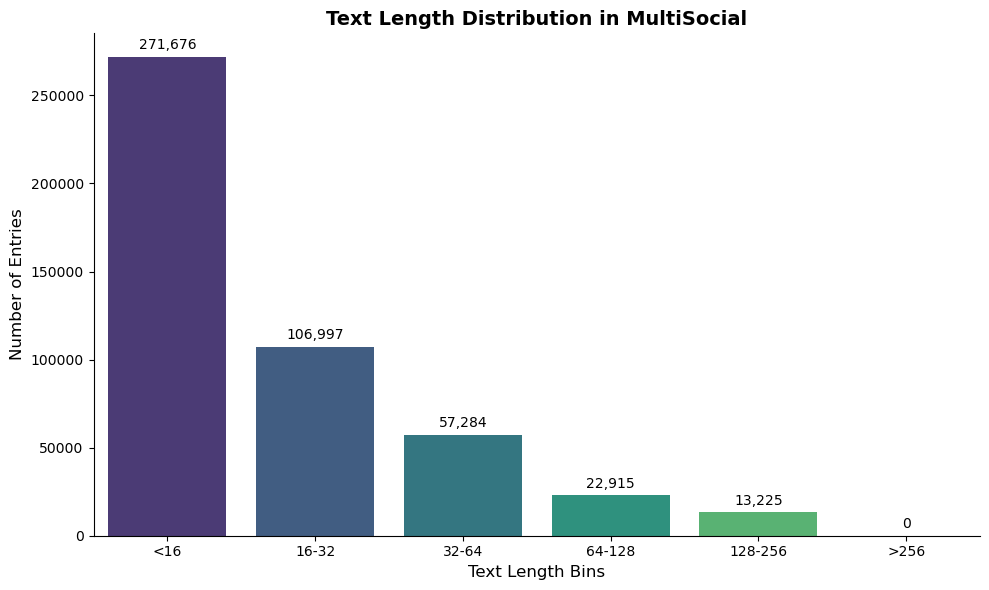

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Define the custom bins and labels
# right=False ensures the intervals are left-inclusive [a, b)
bins = [-float("inf"), 16, 32, 64, 128, 256, float("inf")]
labels = ["<16", "16-32", "32-64", "64-128", "128-256", ">256"]

# 2. Create the binned categories in your DataFrame
ms_df["length_bin"] = pd.cut(
    ms_df["length"], bins=bins, labels=labels, right=False
)

# 3. Calculate value counts and reindex to maintain the exact order
bin_counts = ms_df["length_bin"].value_counts().reindex(labels)

# 4. Generate the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=bin_counts.index,
    y=bin_counts.values,
    palette="viridis",
    hue=bin_counts.index,
    legend=False,
)

# 5. Add titles, labels, and formatting
plt.title("Text Length Distribution in MultiSocial", fontsize=14, fontweight="bold")
plt.xlabel("Text Length Bins", fontsize=12)
plt.ylabel("Number of Entries", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Optional: Add value labels on top of each bar for clarity
for i, v in enumerate(bin_counts.values):
    plt.text(
        i,
        v + (max(bin_counts.values) * 0.01),
        f"{v:,}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

sns.despine()
plt.tight_layout()
plt.show()

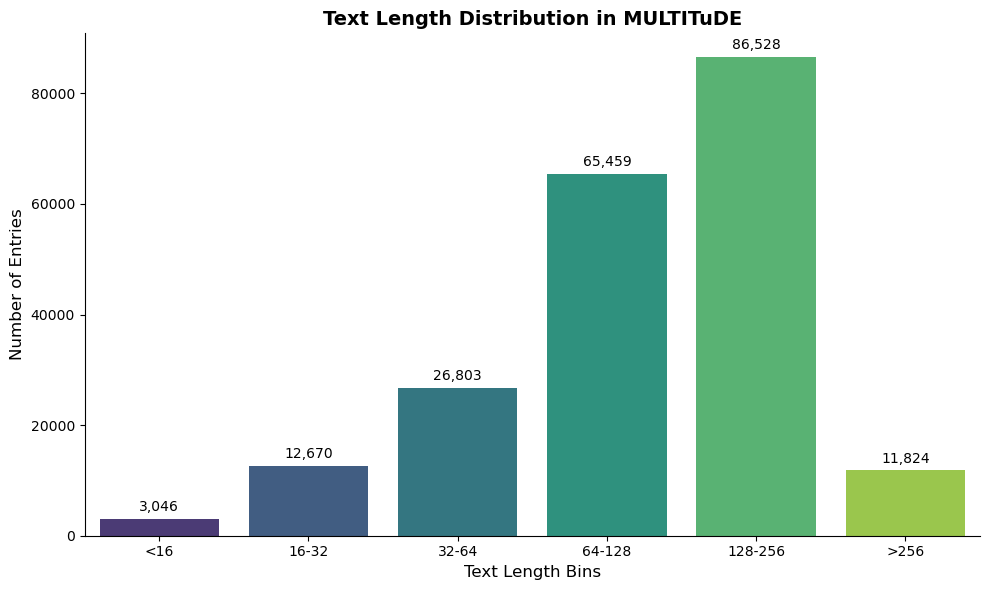

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Define the custom bins and labels
# right=False ensures the intervals are left-inclusive [a, b)
bins = [-float("inf"), 16, 32, 64, 128, 256, float("inf")]
labels = ["<16", "16-32", "32-64", "64-128", "128-256", ">256"]

# 2. Create the binned categories in your DataFrame
mt_df["length_bin"] = pd.cut(
    mt_df["length"], bins=bins, labels=labels, right=False
)

# 3. Calculate value counts and reindex to maintain the exact order
bin_counts = mt_df["length_bin"].value_counts().reindex(labels)

# 4. Generate the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=bin_counts.index,
    y=bin_counts.values,
    palette="viridis",
    hue=bin_counts.index,
    legend=False,
)

# 5. Add titles, labels, and formatting
plt.title("Text Length Distribution in MULTITuDE", fontsize=14, fontweight="bold")
plt.xlabel("Text Length Bins", fontsize=12)
plt.ylabel("Number of Entries", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Optional: Add value labels on top of each bar for clarity
for i, v in enumerate(bin_counts.values):
    plt.text(
        i,
        v + (max(bin_counts.values) * 0.01),
        f"{v:,}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

sns.despine()
plt.tight_layout()
plt.show()